# InternShield

I used the Kaggle file [Real or Fake job postings](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction). `fake_job_postings.csv`, about 18k ads. Label is `fraudulent` (1 = fake).

I want a model I can paste an internship / job offer into and get a fake-risk score. This notebook is the messy part: look at the table, plot it, clean it, train, save `internshield.joblib`. The page you type into is `src/app_gradio.py`. It does not train. It just loads the saved file.


## 0. Load the csv


In [1]:
from __future__ import annotations

import json
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

TEXT_COLS = [
    "title", "location", "department", "company_profile", "description",
    "requirements", "benefits", "employment_type", "required_experience",
    "required_education", "industry", "function",
]
INTERN_HINT = re.compile(r"intern|trainee|placement|summer intern", re.I)

def find_csv() -> Path:
    hits = []
    kaggle = Path("/kaggle/input")
    if kaggle.exists():
        hits.extend(kaggle.rglob("fake_job_postings.csv"))
    here = Path.cwd()
    for root in [here, here / "data", here.parent / "data"]:
        hits.append(root / "fake_job_postings.csv")
    hits.append(Path(r"e:/Pathline Training Academy/Ttask 3 - InternShield/data/fake_job_postings.csv"))
    for p in hits:
        if p.is_file():
            return p
    raise FileNotFoundError("Put fake_job_postings.csv in data/ (or attach the Kaggle dataset)")

def save_dir() -> Path:
    k = Path("/kaggle/working")
    if k.exists():
        out = k / "models"
    else:
        here = Path.cwd()
        if (here / "src").exists() or (here / "data").exists():
            out = here / "models"
        else:
            out = Path(r"e:/Pathline Training Academy/Ttask 3 - InternShield/models")
    out.mkdir(parents=True, exist_ok=True)
    return out

csv_path = find_csv()
raw = pd.read_csv(csv_path)
print("file:", csv_path)
print("shape:", raw.shape)
display(raw.head(3))
display(raw.dtypes.astype(str).to_frame("dtype"))

file: /kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv
shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


,dtype
job_id,int64
title,object
location,object
department,object
salary_range,object
company_profile,object
description,object
requirements,object
benefits,object
telecommuting,int64


## 1. Look at the mess first


In [2]:
print("full-row duplicates:", int(raw.duplicated().sum()))
print("job_id unique:", raw["job_id"].nunique() if "job_id" in raw.columns else "n/a")

print("\nclass counts:")
vc = raw["fraudulent"].value_counts().rename({0: "real", 1: "fake"})
display(vc.to_frame("n"))
print("fake %", round(100 * raw["fraudulent"].mean(), 2))

miss = raw.isna().sum().sort_values(ascending=False)
miss = miss[miss > 0].to_frame("n_missing")
miss["pct"] = (100 * miss["n_missing"] / len(raw)).round(1)
print("\nmissing:")
display(miss)

print("empty description:", int(raw["description"].fillna("").astype(str).str.strip().eq("").sum()))

desc = raw["description"].fillna("")
dup_groups = desc.value_counts()
dup_groups = dup_groups[dup_groups > 1]
print("repeated description groups:", int(len(dup_groups)))
print("rows in those groups:", int(dup_groups.sum()))
print("most copied description shows up:", int(dup_groups.max()) if len(dup_groups) else 0, "times")

raw = raw.copy()
raw["desc_len"] = raw["description"].fillna("").astype(str).str.len()
raw["profile_len"] = raw["company_profile"].fillna("").astype(str).str.len()
print("\ndescription length")
display(raw["desc_len"].describe().to_frame("desc_len").T)
print("salary_range examples:", raw["salary_range"].dropna().head(8).tolist())

full-row duplicates: 0
job_id unique: 17880

class counts:


,n
fraudulent,
real,17014
fake,866


fake % 4.84

missing:


,n_missing,pct
salary_range,15012,84.0
department,11547,64.6
required_education,8105,45.3
benefits,7212,40.3
required_experience,7050,39.4
function,6455,36.1
industry,4903,27.4
employment_type,3471,19.4
company_profile,3308,18.5
requirements,2696,15.1


empty description: 2
repeated description groups: 1190
rows in those groups: 4268
most copied description shows up: 379 times

description length


,count,mean,std,min,25%,50%,75%,max
desc_len,17880.0,1218.004418,894.82862,0.0,607.0,1017.0,1586.0,14907.0


salary_range examples: ['20000-28000', '100000-120000', '120000-150000', '100000-120000', '50000-65000', '40000-50000', '60-80', '65000-70000']


What I saw:

- 0 exact duplicate rows, and every `job_id` is unique, so at first I thought duplicates were fine
- they are not. Same `description` is reused. 1190 groups, 4268 rows sitting in them, one ad copied 379 times. If I leave that, train and test can share the same text and the score looks better than it is
- fake is about 4.8%. Accuracy is going to look high no matter what
- `salary_range` is empty on 84% of rows. `department` 65%. I am not dropping those columns. Empty can mean something
- 2 rows with no description. Those I will just delete
- salary values are mixed (`20000-28000` and `60-80`) so I am not parsing them into numbers. I only keep a flag if salary was left blank


## 2. Plots (raw)


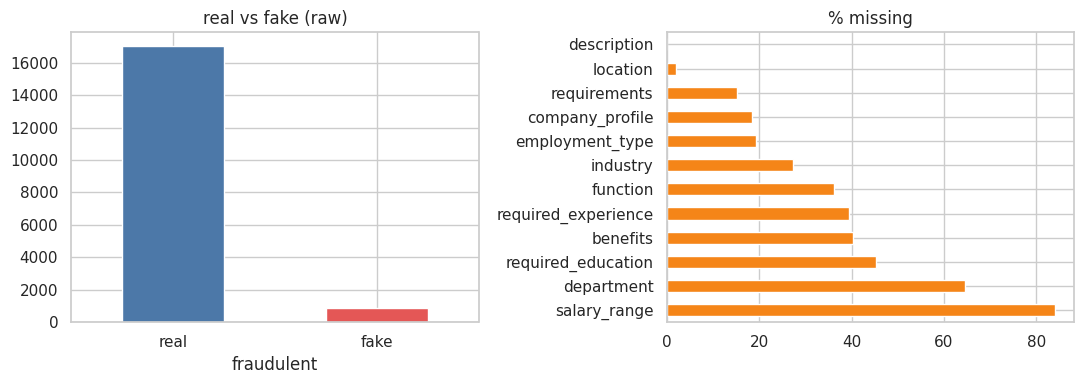

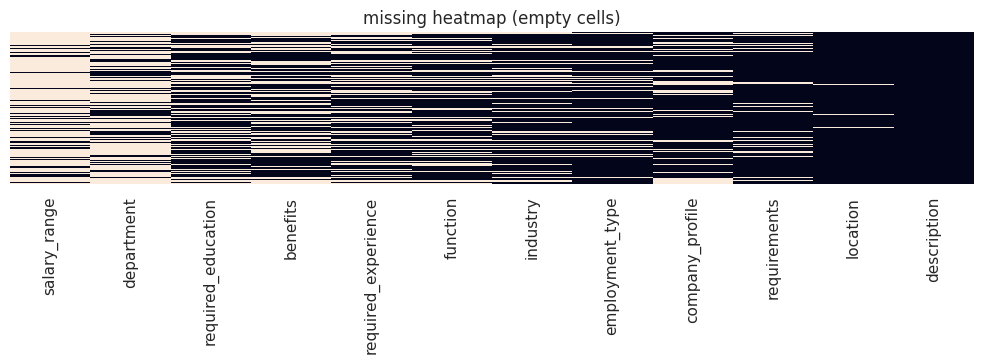

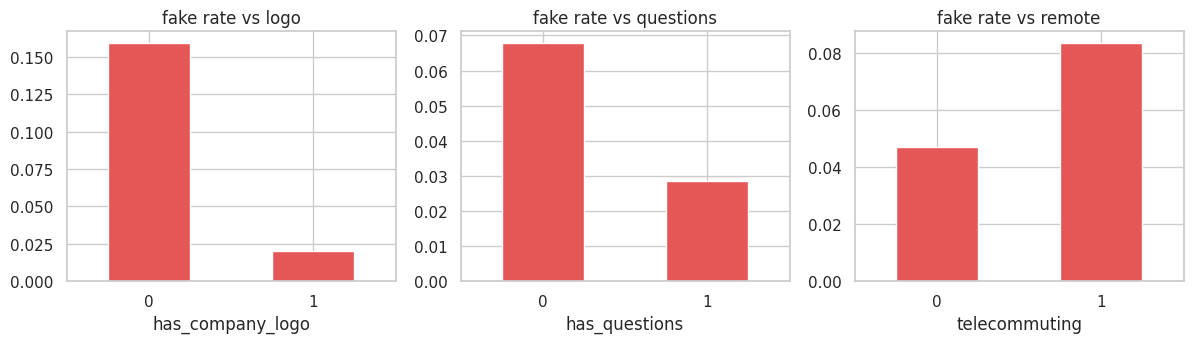

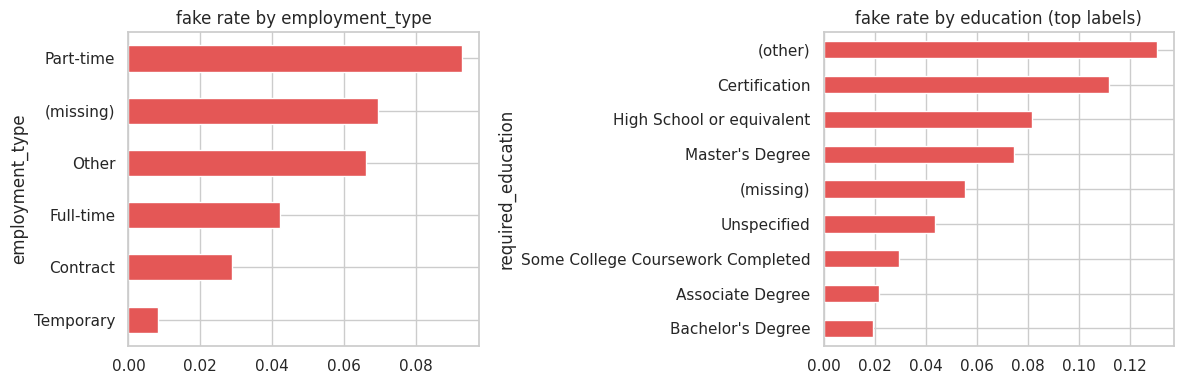

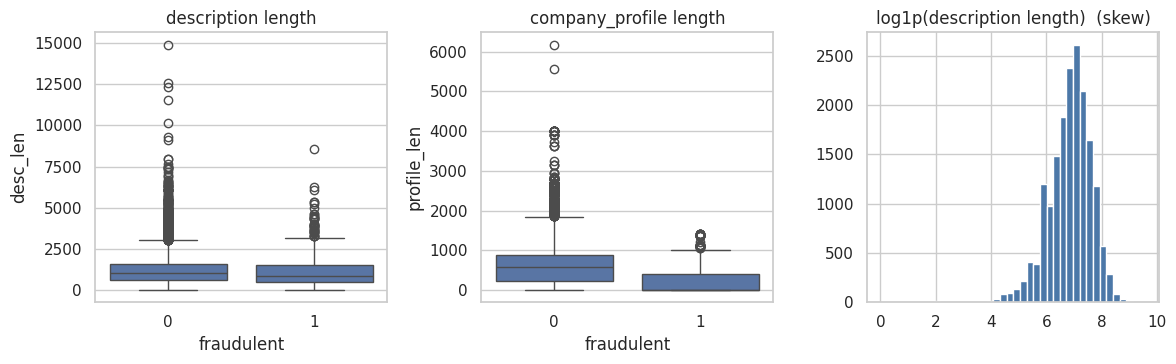

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw["fraudulent"].map({0: "real", 1: "fake"}).value_counts().plot(
    kind="bar", ax=axes[0], color=["#4c78a8", "#e45756"]
)
axes[0].set_title("real vs fake (raw)")
axes[0].tick_params(axis="x", rotation=0)
miss["pct"].plot(kind="barh", ax=axes[1], color="#f58518")
axes[1].set_title("% missing")
plt.tight_layout()
plt.show()

miss_cols = list(miss.index)
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(raw[miss_cols].isna(), cbar=False, yticklabels=False, ax=ax)
ax.set_title("missing heatmap (empty cells)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col, title in zip(
    axes,
    ["has_company_logo", "has_questions", "telecommuting"],
    ["fake rate vs logo", "fake rate vs questions", "fake rate vs remote"],
):
    pd.crosstab(raw[col], raw["fraudulent"], normalize="index")[1].plot(kind="bar", ax=ax, color="#e45756")
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
emp = raw["employment_type"].fillna("(missing)")
pd.crosstab(emp, raw["fraudulent"], normalize="index")[1].sort_values().plot(
    kind="barh", ax=axes[0], color="#e45756"
)
axes[0].set_title("fake rate by employment_type")
edu = raw["required_education"].fillna("(missing)")
top_edu = edu.value_counts().head(8).index
pd.crosstab(edu.where(edu.isin(top_edu), "(other)"), raw["fraudulent"], normalize="index")[1].sort_values().plot(
    kind="barh", ax=axes[1], color="#e45756"
)
axes[1].set_title("fake rate by education (top labels)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
sns.boxplot(data=raw, x="fraudulent", y="desc_len", ax=axes[0], showfliers=True)
axes[0].set_title("description length")
sns.boxplot(data=raw, x="fraudulent", y="profile_len", ax=axes[1], showfliers=True)
axes[1].set_title("company_profile length")
axes[2].hist(np.log1p(raw["desc_len"]), bins=40, color="#4c78a8")
axes[2].set_title("log1p(description length)  (skew)")
plt.tight_layout()
plt.show()

No logo is the one that jumped out. Part-time and missing employment type also look a bit worse than full-time.

Description length is skewed (long tail). A couple of ads are huge. I will cap length using the train 99th percentile later, then take log. I am not deleting those rows. They are still real ads, just long.


## 3. Missing values


In [4]:
df = raw.copy()
for col in TEXT_COLS + ["salary_range"]:
    if col in df.columns:
        df[col] = df[col].fillna("")
for col in ["telecommuting", "has_company_logo", "has_questions", "fraudulent"]:
    df[col] = df[col].fillna(0).astype(int)

print("nulls in text cols after fill:", int(df[TEXT_COLS].isna().sum().sum()))
print("nulls in salary_range:", int(df["salary_range"].isna().sum()))
display(df[TEXT_COLS + ["salary_range"]].isna().sum().to_frame("n_missing"))

nulls in text cols after fill: 0
nulls in salary_range: 0


,n_missing
title,0
location,0
department,0
company_profile,0
description,0
requirements,0
benefits,0
employment_type,0
required_experience,0
required_education,0


I filled empty text with `""`, not a random word. All of that text gets concatenated for TF-IDF anyway, and I still keep separate flags for “no company profile” / “no salary”.

I did not drop `salary_range` even though it is mostly empty.


## 4. Bad rows and copied ads


empty description rows: 2
rows: 17880 -> drop empty desc 17878 -> unique descriptions 14800
fake left: 630   fake % 4.26


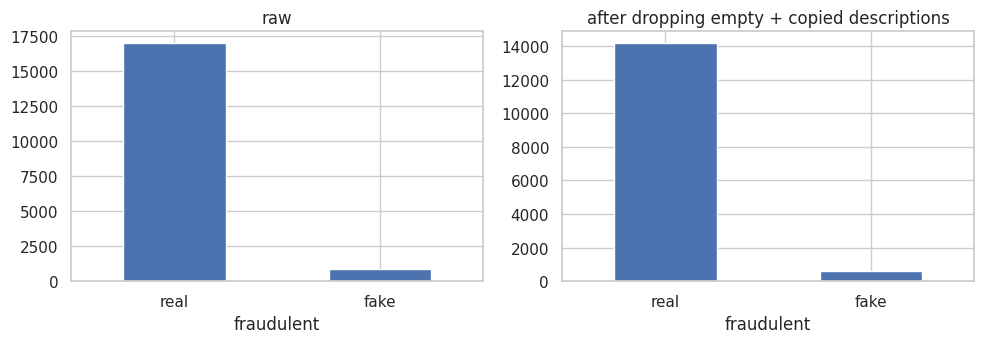

In [5]:
n0 = len(df)
empty_desc = df["description"].astype(str).str.strip() == ""
print("empty description rows:", int(empty_desc.sum()))
df = df.loc[~empty_desc].reset_index(drop=True)

n1 = len(df)
df = df.drop_duplicates(subset=["description"], keep="first").reset_index(drop=True)
print("rows:", n0, "-> drop empty desc", n1, "-> unique descriptions", len(df))
print("fake left:", int(df["fraudulent"].sum()), "  fake %", round(100 * df["fraudulent"].mean(), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
raw["fraudulent"].map({0: "real", 1: "fake"}).value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("raw")
axes[0].tick_params(axis="x", rotation=0)
df["fraudulent"].map({0: "real", 1: "fake"}).value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("after dropping empty + copied descriptions")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

I kept one copy of each description. The class is still around 4% fake. Dedup is not how I fix imbalance. That comes after the split.


## 5. Extra flags I added


In [6]:
def combine_text(row: pd.Series) -> str:
    parts = []
    for col in TEXT_COLS:
        val = row.get(col, "")
        if pd.notna(val) and str(val).strip():
            parts.append(str(val))
    return " \n ".join(parts)

def numeric_row(row: pd.Series, text: str) -> np.ndarray:
    profile = str(row.get("company_profile", "") or "")
    salary = str(row.get("salary_range", "") or "")
    title = str(row.get("title", "") or "")
    return np.array(
        [
            int(row.get("telecommuting", 0) or 0),
            int(row.get("has_company_logo", 0) or 0),
            int(row.get("has_questions", 0) or 0),
            int(len(profile.strip()) < 40),
            int(len(salary.strip()) == 0),
            int(bool(INTERN_HINT.search(title + " " + text))),
            np.log1p(len(text)),
        ],
        dtype=float,
    )

texts = df.apply(combine_text, axis=1).tolist()
nums = np.vstack([numeric_row(row, t) for (_, row), t in zip(df.iterrows(), texts)])
print("built text + 7 numeric flags for", len(df), "rows")
print("flag names: telecommuting, logo, questions, thin_profile, no_salary, intern_like, log_text_len")

built text + 7 numeric flags for 14800 rows
flag names: telecommuting, logo, questions, thin_profile, no_salary, intern_like, log_text_len


`thin_profile` = company_profile shorter than 40 characters. `no_salary` = salary field blank. `intern_like_title` = intern/trainee in the title or text.

I am not plotting fake rates here yet. I wait until after the split and use **train only**, so test does not leak into what I “noticed”.


## 6. Train / test split


train 11840 fake 504 rate 0.043
test  2960 fake 126 rate 0.043

fake rates on TRAIN only:


,flag,when_0,when_1
0,telecommuting,0.042,0.055
1,has_company_logo,0.140,0.017
2,has_questions,0.057,0.027
3,thin_profile,0.016,0.148
4,no_salary,0.072,0.036
5,intern_like_title,0.049,0.033


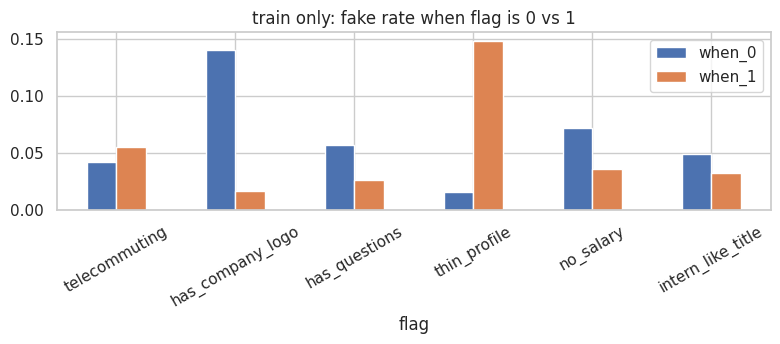

In [7]:
y = df["fraudulent"].astype(int).to_numpy()
idx = np.arange(len(df))
tr, te = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
print("train", len(tr), "fake", int(y[tr].sum()), "rate", round(y[tr].mean(), 3))
print("test ", len(te), "fake", int(y[te].sum()), "rate", round(y[te].mean(), 3))

flag_names = [
    "telecommuting",
    "has_company_logo",
    "has_questions",
    "thin_profile",
    "no_salary",
    "intern_like_title",
]
flag_df = pd.DataFrame(nums[tr, :6], columns=flag_names)
flag_df["fraudulent"] = y[tr]
rates = []
for c in flag_names:
    g = flag_df.groupby(c)["fraudulent"].mean()
    rates.append({"flag": c, "when_0": round(float(g.get(0, np.nan)), 3), "when_1": round(float(g.get(1, np.nan)), 3)})
print("\nfake rates on TRAIN only:")
display(pd.DataFrame(rates))

fig, ax = plt.subplots(figsize=(8, 3.6))
pd.DataFrame(rates).set_index("flag")[["when_0", "when_1"]].plot(kind="bar", ax=ax)
ax.set_title("train only: fake rate when flag is 0 vs 1")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Split is 80/20, stratified, seed 42. Cap and oversample come after this.

On train, no-logo and thin_profile are the useful ones. `no_salary` and `intern_like_title` went the other way from what I expected (blank salary / intern wording were *less* fake here). I still keep the flags. The model can put a small weight on them.


## 7. Outliers and skew (train stats only)


train description/combined-text length p99: 7134
how many rows above that (whole table): 154


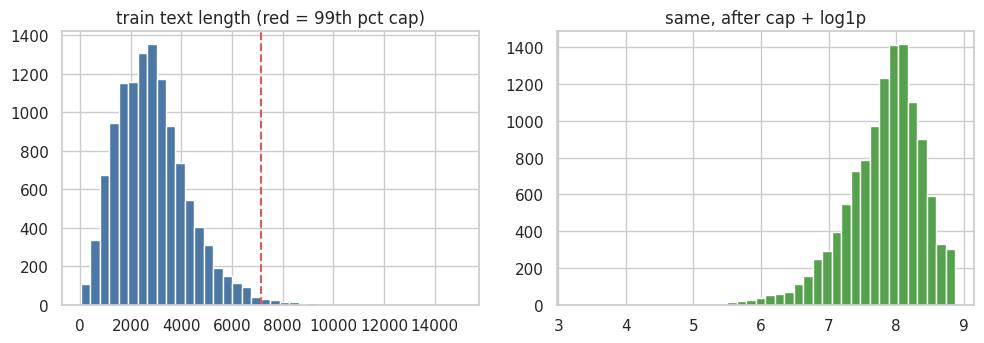

In [8]:
raw_len = np.array([len(t) for t in texts], dtype=float)
p99 = float(np.percentile(raw_len[tr], 99))
print("train description/combined-text length p99:", round(p99))
print("how many rows above that (whole table):", int((raw_len > p99).sum()))

nums = nums.copy()
nums[:, -1] = np.log1p(np.minimum(raw_len, p99))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(raw_len[tr], bins=40, color="#4c78a8")
axes[0].axvline(p99, color="#e45756", linestyle="--")
axes[0].set_title("train text length (red = 99th pct cap)")
axes[1].hist(nums[tr, -1], bins=40, color="#54a24b")
axes[1].set_title("same, after cap + log1p")
plt.tight_layout()
plt.show()

I capped combined text length at the train 99th percentile, then log1p, then I will scale it with StandardScaler (also train-only). I did not drop the long ads.


## 8. Class balance (train only)


train before 11840 fake 504 real 11336
test left as-is 2960 fake 126
train after 22672 fake 11336 real 11336


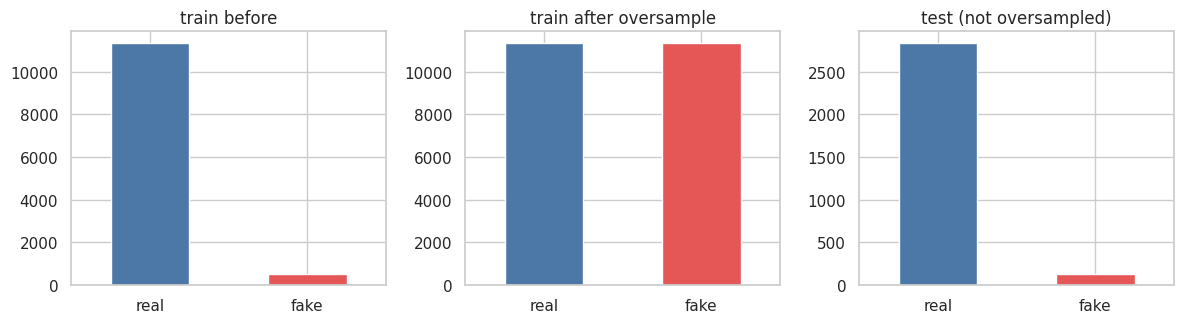

In [9]:
def oversample_train_idx(tr, y, seed=SEED):
    tr_real = tr[y[tr] == 0]
    tr_fake = tr[y[tr] == 1]
    tr_fake_up = resample(tr_fake, replace=True, n_samples=len(tr_real), random_state=seed)
    out = np.concatenate([tr_real, tr_fake_up])
    rng = np.random.default_rng(seed)
    rng.shuffle(out)
    return out

print("train before", len(tr), "fake", int(y[tr].sum()), "real", int((y[tr] == 0).sum()))
print("test left as-is", len(te), "fake", int(y[te].sum()))

tr_bal = oversample_train_idx(tr, y)
print("train after", len(tr_bal), "fake", int(y[tr_bal].sum()), "real", int((y[tr_bal] == 0).sum()))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
pd.Series(y[tr]).map({0: "real", 1: "fake"}).value_counts().plot(kind="bar", ax=axes[0], color=["#4c78a8", "#e45756"])
axes[0].set_title("train before")
axes[0].tick_params(axis="x", rotation=0)
pd.Series(y[tr_bal]).map({0: "real", 1: "fake"}).value_counts().plot(kind="bar", ax=axes[1], color=["#4c78a8", "#e45756"])
axes[1].set_title("train after oversample")
axes[1].tick_params(axis="x", rotation=0)
pd.Series(y[te]).map({0: "real", 1: "fake"}).value_counts().plot(kind="bar", ax=axes[2], color=["#4c78a8", "#e45756"])
axes[2].set_title("test (not oversampled)")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

I copied fake train rows until they matched the real count. Test stays ~4% fake on purpose.

That does copy the same 504 fake ads a lot of times. Later I print train-with-copies vs train-unique vs test so I can see if it just memorized those copies.

I did not oversample the whole csv first. That would copy the same fake ad into both sides.

I am not also using `class_weight="balanced"`. Train is already 50/50 now.


## 9. Train


In [10]:
vec = TfidfVectorizer(max_features=25000, ngram_range=(1, 2), min_df=3, stop_words="english")
x_text_tr = vec.fit_transform([texts[i] for i in tr_bal])
scaler = StandardScaler()
x_num_tr = scaler.fit_transform(nums[tr_bal])
x_tr = hstack([x_text_tr, csr_matrix(x_num_tr)])

clf = LogisticRegression(max_iter=400, C=1.5, solver="liblinear")
clf.fit(x_tr, y[tr_bal])

def score_idx(idx):
    x = hstack(
        [
            vec.transform([texts[i] for i in idx]),
            csr_matrix(scaler.transform(nums[idx])),
        ]
    )
    proba = clf.predict_proba(x)[:, 1]
    pred = (proba >= 0.5).astype(int)
    yt = y[idx]
    fake_rec = float(((pred == 1) & (yt == 1)).sum() / max((yt == 1).sum(), 1))
    return {
        "auc": float(roc_auc_score(yt, proba)),
        "fake_recall": fake_rec,
        "acc": float((pred == yt).mean()),
        "y": yt,
        "pred": pred,
        "proba": proba,
    }

fit_set = score_idx(tr_bal)
train_unique = score_idx(tr)
test = score_idx(te)

print("=== fitted train (with copied fakes) ===")
print(classification_report(fit_set["y"], fit_set["pred"], target_names=["real", "fake"], digits=3))
print("auc", round(fit_set["auc"], 3))
print()
print("=== train unique (same ads, no copies) ===")
print(classification_report(train_unique["y"], train_unique["pred"], target_names=["real", "fake"], digits=3))
print("auc", round(train_unique["auc"], 3))
print()
print("=== test ===")
print(classification_report(test["y"], test["pred"], target_names=["real", "fake"], digits=3))
print("auc", round(test["auc"], 3))

cmp = pd.DataFrame(
    [
        {"set": "train (copied fakes)", **{k: fit_set[k] for k in ("acc", "fake_recall", "auc")}},
        {"set": "train unique", **{k: train_unique[k] for k in ("acc", "fake_recall", "auc")}},
        {"set": "test", **{k: test[k] for k in ("acc", "fake_recall", "auc")}},
    ]
)
display(cmp.round(3))

y_true, pred, proba = test["y"], test["pred"], test["proba"]
fake_recall = test["fake_recall"]

=== fitted train (with copied fakes) ===
              precision    recall  f1-score   support

        real      1.000     0.989     0.994     11336
        fake      0.989     1.000     0.995     11336

    accuracy                          0.994     22672
   macro avg      0.995     0.994     0.994     22672
weighted avg      0.995     0.994     0.994     22672

auc 1.0

=== train unique (same ads, no copies) ===
              precision    recall  f1-score   support

        real      1.000     0.989     0.994     11336
        fake      0.801     1.000     0.890       504

    accuracy                          0.989     11840
   macro avg      0.901     0.994     0.942     11840
weighted avg      0.992     0.989     0.990     11840

auc 1.0

=== test ===
              precision    recall  f1-score   support

        real      0.994     0.980     0.987      2834
        fake      0.659     0.857     0.745       126

    accuracy                          0.975      2960
   macro avg 

,set,acc,fake_recall,auc
0,train (copied fakes),0.994,1.000,1.000
1,train unique,0.989,1.000,1.000
2,test,0.975,0.857,0.991


TF-IDF on the ad text (1-2 word phrases, 25k features). Fit on train only.

I stuck the 7 numbers next to it (logo, questions, remote, thin profile, no salary, intern-like, log length).

Logistic regression because it is small enough to save as one joblib file for the app.


## 10. Overfit check + test plots


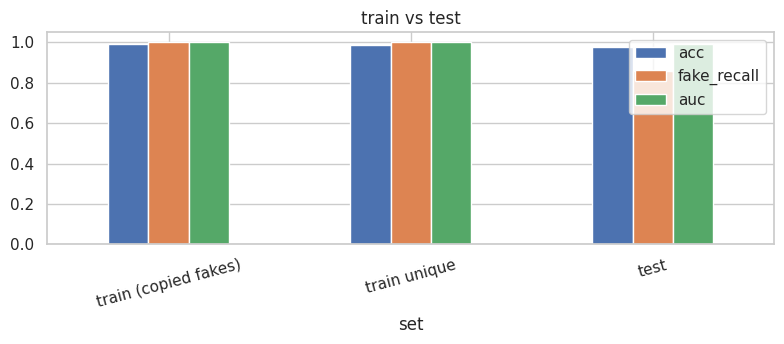

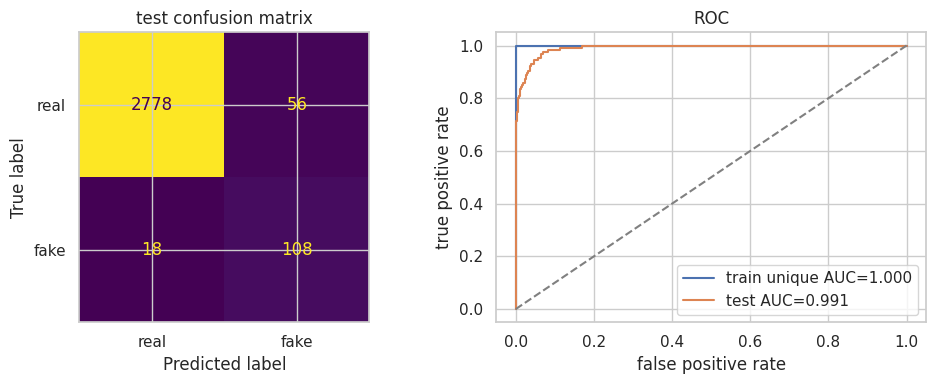

test fake recall 0.857
AUC gap (copied-train minus test) 0.009


In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cmp.set_index("set")[["acc", "fake_recall", "auc"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("train vs test")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_true, pred)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("test confusion matrix")

for lab, s, style in [
    ("train unique", train_unique, "-"),
    ("test", test, "-"),
]:
    fpr, tpr, _ = roc_curve(s["y"], s["proba"])
    axes[1].plot(fpr, tpr, style, label=f"{lab} AUC={s['auc']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC")
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].legend()
plt.tight_layout()
plt.show()

print("test fake recall", round(fake_recall, 3))
gap = fit_set["auc"] - test["auc"]
print("AUC gap (copied-train minus test)", round(gap, 3))

How I read this:

- **Underfit** would be train *and* test both weak (like 0.6 AUC). That is not what I have.
- **Overfit** is train much better than test.
- The copied train is almost perfect. That is a bit unfair: I showed the same fake ads many times while fitting, so of course it looks 1.0 there.
- **Train unique** (the real train ads, one copy each) vs **test** is the honest comparison. If those two are close, the model is fine. If unique train is ~1.0 and test fake-recall drops a lot, then yes, a little overfit.

I already expect a small gap. I copied 504 fake train ads until they matched 11k real ones, so the model can memorize those fake wordings. Test is still high on this Kaggle file (logo / empty profile separate a lot of fakes). So: **not underfit. A little overfit. Test is still usable as a screening score.**


## 11. Save the model


In [12]:
MODELS = save_dir()
bundle = {
    "vec": vec,
    "scaler": scaler,
    "clf": clf,
    "num_names": [
        "telecommuting",
        "has_company_logo",
        "has_questions",
        "thin_profile",
        "no_salary",
        "intern_like_title",
        "log_text_len",
    ],
    "text_len_p99": p99,
}
out_path = MODELS / "internshield.joblib"
joblib.dump(bundle, out_path)
metrics = {
    "n": int(len(df)),
    "n_fake": int(y.sum()),
    "n_train_before_oversample": int(len(tr)),
    "n_train_after_oversample": int(len(tr_bal)),
    "text_len_p99": p99,
    "train_copied_auc": fit_set["auc"],
    "train_unique_auc": train_unique["auc"],
    "train_unique_fake_recall": train_unique["fake_recall"],
    "test_auc": float(test["auc"]),
    "test_fake_recall": fake_recall,
}
(MODELS / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("saved", out_path)
print("size_mb", round(out_path.stat().st_size / 1e6, 2))
print(metrics)

saved /kaggle/working/models/internshield.joblib
size_mb 1.29
{'n': 14800, 'n_fake': 630, 'n_train_before_oversample': 11840, 'n_train_after_oversample': 22672, 'text_len_p99': 7134.440000000002, 'train_copied_auc': 0.9999376443991675, 'train_unique_auc': 0.9999285882313406, 'train_unique_fake_recall': 1.0, 'test_auc': 0.9906856649975916, 'test_fake_recall': 0.8571428571428571}


## 12. The app (after this notebook)


Once `internshield.joblib` is there:

```text
python src/app_gradio.py
```

or

```text
python src/app_cli.py
```

Need `pip install -r requirements.txt` once. Do not retrain every time someone pastes an offer.


In [4]:
loaded = joblib.load(out_path)
print("bundle keys:", list(loaded.keys()))
print("tfidf vocab:", len(loaded["vec"].get_feature_names_out()))
print("ok")

NameError: name 'joblib' is not defined